# MSCA681 Tutorial 6: Dimensionality Reduction

The dimensionality of a model is the number of predictors or input variables used by the model. The curse of dimensionality is the affliction caused by adding variables to multivariate data models. As variables are added, the data space becomes increasingly sparse, and classification and prediction models fail because the available data are insufficient to provide a useful model across so many variables. One of the key steps in data mining, therefore, is finding ways to reduce dimensionality with minimal sacrifice of accuracy. In the artificial intelligence literature, dimension reduction is often referred to as factor selection or feature extraction. Generally, it refers to techniques that reduce the number of input variables in a dataset.

We will cover: 
1. Correlation Analysis
2. Reducing the Number of Categories in Categorical Variables
3. Converting a Categorical Variable to a Numerical Variable
4. Principal Component Analysis (PCA)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# The Bank Marketing Dataset

The data is related to direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).
It has a mix of numerical and categorical features, which makes it perfect for practicing both correlation analysis and categorical preprocessing.

## Step 1: Load the dataset

In [2]:
bank_df = pd.read_csv("bank.csv")

bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [3]:
bank_df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


Before we do any modeling or PCA, it’s important to understand what types of variables we’re working with. Separating them helps us decide which preprocessing steps to apply, because numerical data often needs scaling, while categorical data usually needs encoding.

In [4]:
# Separate numerical and categorical variables
num_cols = bank_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = bank_df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

Numerical Columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical Columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


## Visualizations

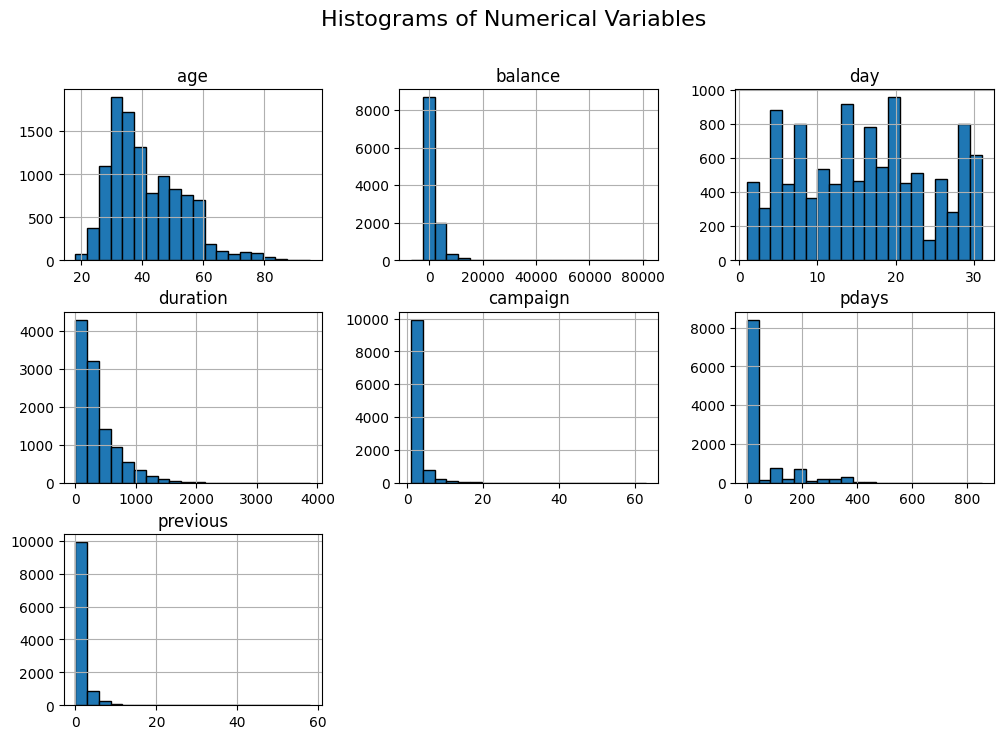

In [5]:
# Plot histograms for all numerical columns
bank_df[num_cols].hist(bins=20, figsize=(12, 8), edgecolor="black")
plt.suptitle("Histograms of Numerical Variables", fontsize=16)
plt.show()

Task 1: Which variables should be transform and why?

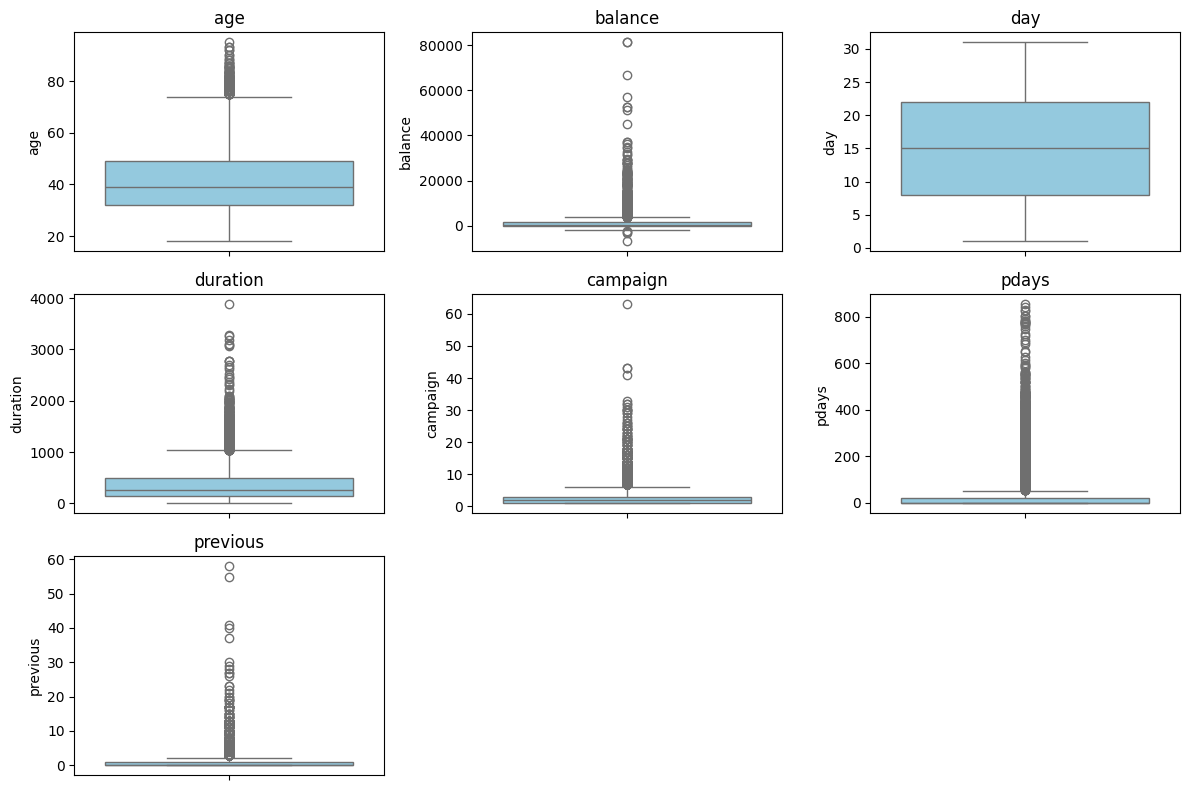

In [6]:
# Boxplots for numerical variables
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=bank_df[col], color="skyblue")
    plt.title(col)
plt.tight_layout()
plt.show()

C:\Users\moeka\AppData\Local\Temp\ipykernel_15816\3118398878.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=bank_df[col], palette="viridis", order=bank_df[col].value_counts().index)
C:\Users\moeka\AppData\Local\Temp\ipykernel_15816\3118398878.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=bank_df[col], palette="viridis", order=bank_df[col].value_counts().index)
C:\Users\moeka\AppData\Local\Temp\ipykernel_15816\3118398878.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=bank_df[col], palette="viridis", order=bank_df[c

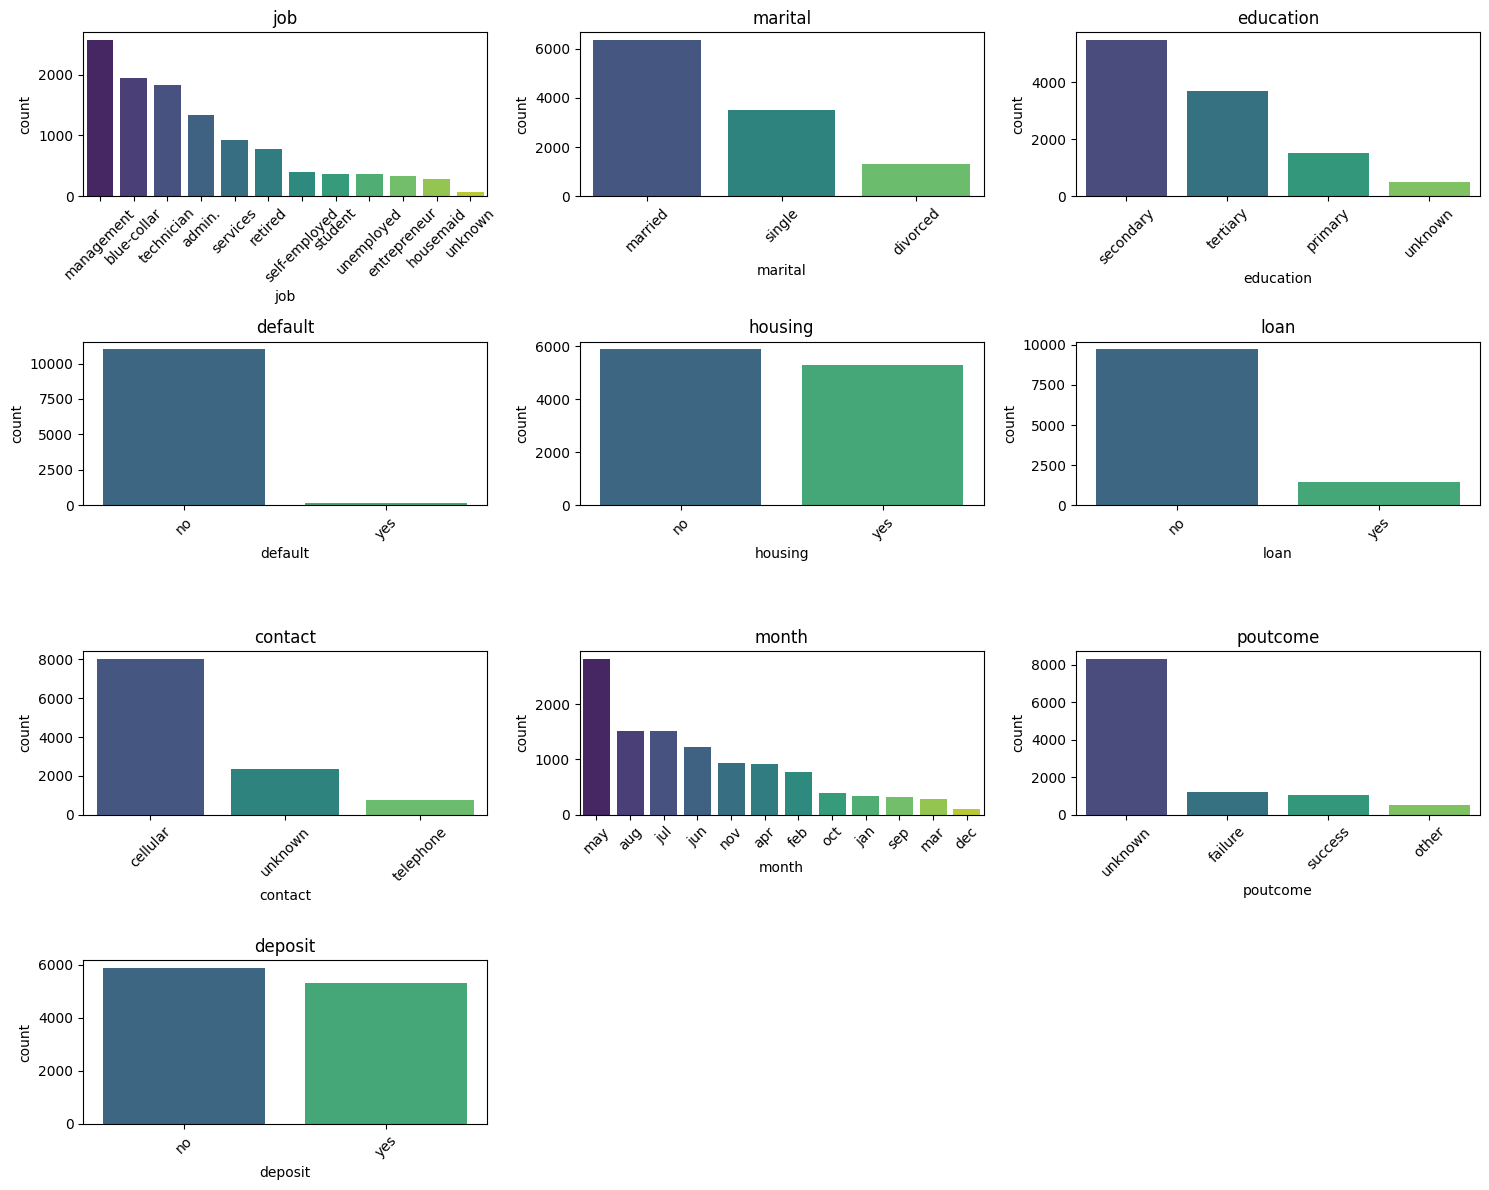

In [7]:
# Bar plots for categorical variables
plt.figure(figsize=(15, 12))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(4, 3, i)
    sns.countplot(x=bank_df[col], palette="viridis", order=bank_df[col].value_counts().index)
    plt.title(col)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

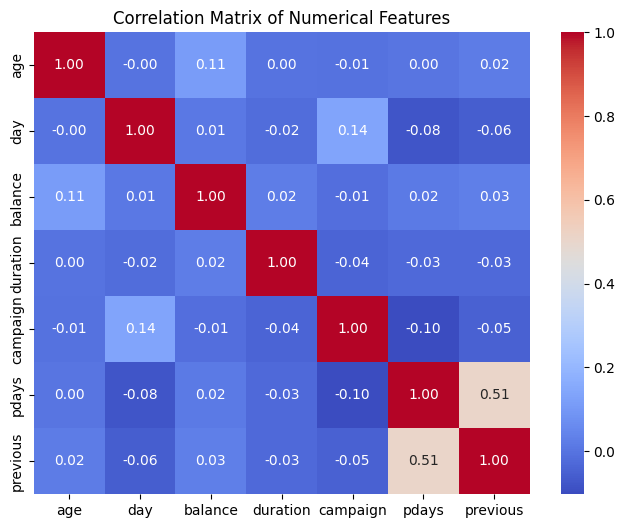

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['age', 'day', 'balance', 'duration', 'campaign', 'pdays', 'previous']

plt.figure(figsize=(8,6))
sns.heatmap(bank_df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [9]:
# Example: simplify 'education'
bank_df['education'] = bank_df['education'].replace(
    ['basic.4y', 'basic.6y', 'basic.9y'], 'basic'
)

# Example: simplify 'job'
bank_df['job'] = bank_df['job'].replace(
    ['admin.', 'management', 'entrepreneur', 'self-employed'], 'white-collar'
)
bank_df['job'] = bank_df['job'].replace(
    ['blue-collar', 'technician', 'services'], 'blue-collar'
)
bank_df['job'] = bank_df['job'].replace(
    ['student', 'retired', 'unemployed'], 'other'
)

In [10]:
# Separate features and target
X = bank_df.drop("deposit", axis=1)
y = bank_df["deposit"]

In [11]:
# Encode binary categorical vars
bank_df['default'] = bank_df['default'].map({'yes':1, 'no':0})
bank_df['housing'] = bank_df['housing'].map({'yes':1, 'no':0})
bank_df['loan'] = bank_df['loan'].map({'yes':1, 'no':0})
bank_df['deposit'] = bank_df['deposit'].map({'yes':1, 'no':0})  # target

# One-hot encode the rest
X = pd.get_dummies(bank_df.drop("deposit", axis=1),
                   columns=['job', 'marital', 'education', 'contact', 'month', 'poutcome'],
                   drop_first=True)

y = bank_df['deposit']

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Logistic Regression (without PCA)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print("Accuracy (without PCA):", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy (without PCA): 0.8274111675126904
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1762
           1       0.83      0.80      0.81      1587

    accuracy                           0.83      3349
   macro avg       0.83      0.83      0.83      3349
weighted avg       0.83      0.83      0.83      3349



Usually, we apply PCA on numerical variables only. However, we will apply it here on all the variablesc (numerical + binary). For binary variables, there are better DR techniques.

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)

train_components = pca.fit_transform(X_train)
test_components = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Principal components:", train_components.shape[1])

Original features: 35
Principal components: 19


In [25]:
# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio:", explained_variance)
print("Cumulative Variance:", explained_variance.cumsum())

Explained Variance Ratio: [0.17152209 0.11868643 0.11105379 0.09953708 0.09276049 0.08617956
 0.05053804 0.04832773 0.03687107 0.02919673 0.01968395 0.01691981
 0.01434622 0.01170204 0.01067287 0.009552   0.0084602  0.00789154
 0.00722403]
Cumulative Variance: [0.17152209 0.29020853 0.40126232 0.5007994  0.59355989 0.67973944
 0.73027748 0.77860521 0.81547628 0.84467301 0.86435696 0.88127677
 0.895623   0.90732504 0.9179979  0.9275499  0.9360101  0.94390164
 0.95112567]


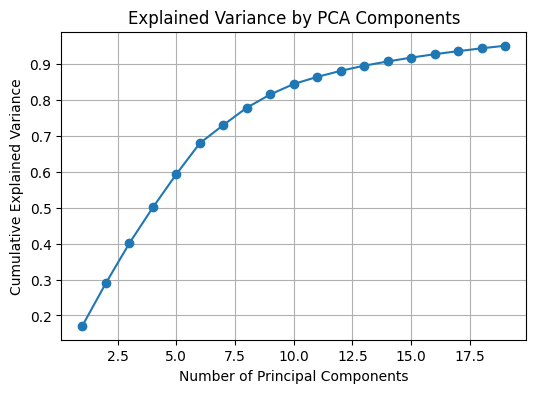

In [26]:
# Visualize explained variance

plt.figure(figsize=(6,4))
plt.plot(range(1, 20), explained_variance.cumsum(), marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance by PCA Components")
plt.grid(True)
plt.show()

In [27]:
# Logistic Regression (with PCA)
log_reg_pca = LogisticRegression(max_iter=1000, random_state=42)
log_reg_pca.fit(train_components, y_train)

y_pred_pca = log_reg_pca.predict(test_components)

print("Accuracy (with PCA):", accuracy_score(y_test, y_pred_pca))
print(classification_report(y_test, y_pred_pca))

Accuracy (with PCA): 0.8041206330247835
              precision    recall  f1-score   support

           0       0.80      0.84      0.82      1762
           1       0.81      0.76      0.79      1587

    accuracy                           0.80      3349
   macro avg       0.80      0.80      0.80      3349
weighted avg       0.80      0.80      0.80      3349



PCA doesn’t always make the model more accurate, but it makes it simpler and just as powerful, which is very valuable in real-world machine learning.